<small>Dataset: Student_Performance.csv</small>

# Q26. Student K Means

Discover groups using K-Means, choose K from an elbow plot and explain the group profiles.


## Question from Classroom

Student Grouping Using K-Means 
Problem statement: Group students into clusters according to their academic performance. 
Tasks to be performed: 
1. Load a numerical dataset containing student academic attributes. 
2. Select at least three relevant features, such as attendance, internal marks and 
assignment scores. 
3. Standardize the selected features. 
4. Apply the elbow method to select a suitable cluster count. 
5. Train and Visualize the clusters using a suitable two-dimensional projection. 
6. Interpret the cluster profiles without treating the clusters as definitive measures of 
ability.


## Understand before coding

Select features -> inspect/impute -> scale -> fit K=2..8 -> inspect elbow -> choose K -> plot and describe centroids/counts.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 6 listed tasks → 6 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a numerical dataset containing student academic attributes.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
df=pd.read_csv("data/Student_Performance.csv")


## Task 2. Select at least three relevant features, such as attendance, internal marks and assignment scores.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
features=["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced"]
X=df[features]
print(X.head())


   Hours Studied  ...  Sample Question Papers Practiced
0              7  ...                                 1
1              4  ...                                 2
2              8  ...                                 2
3              5  ...                                 2
4              7  ...                                 5

[5 rows x 4 columns]


## Task 3. Standardize the selected features.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
imputer=SimpleImputer(strategy="median")
clean=imputer.fit_transform(X)
scaler=StandardScaler()
scaled=scaler.fit_transform(clean)


## Task 4. Apply the elbow method to select a suitable cluster count.

This block implements the task above. Variables from earlier blocks are reused.


 K      Inertia
 2 32290.802999
 3 27746.180179
 4 24106.758086
 5 21356.622271
 6 19377.813249
 7 17525.248323
 8 15573.965897


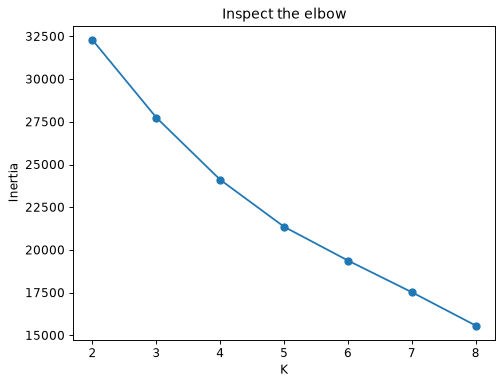

In [4]:
candidate_k=list(range(2,9))
inertias=[]
for k in candidate_k:
    trial=KMeans(n_clusters=k,n_init=10,random_state=42).fit(scaled)
    inertias.append(trial.inertia_)
print(pd.DataFrame({"K":candidate_k,"Inertia":inertias}).to_string(index=False))
plt.plot(candidate_k,inertias,"o-")
plt.xlabel("K");plt.ylabel("Inertia");plt.title("Inspect the elbow");plt.show()


## Task 5. Train and Visualize the clusters using a suitable two-dimensional projection.

This block implements the task above. Variables from earlier blocks are reused.


Choose K after inspecting the elbow [3]: 


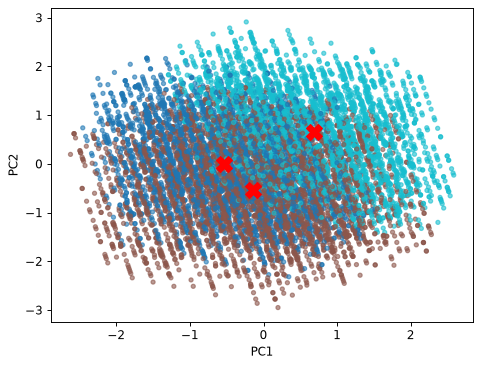

In [5]:
k=int(input("Choose K after inspecting the elbow [3]: ") or "3")
if not 2<=k<=8:raise ValueError("Choose K from 2 to 8 for this practice example")
model=KMeans(n_clusters=k,n_init=10,random_state=42).fit(scaled)

# Cluster on all four features; PCA is only for displaying a two-dimensional view.
projection=PCA(n_components=2)
points=projection.fit_transform(scaled)
centers=projection.transform(model.cluster_centers_)
plt.scatter(points[:,0],points[:,1],c=model.labels_,cmap="tab10",s=12,alpha=0.6)
plt.scatter(centers[:,0],centers[:,1],marker="X",c="red",s=180)
plt.xlabel("PC1");plt.ylabel("PC2");plt.show()


## Task 6. Interpret the cluster profiles without treating the clusters as definitive measures of ability.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
profile=pd.DataFrame(clean,columns=features)
profile["Cluster"]=model.labels_
print("Record counts:\n",profile["Cluster"].value_counts().sort_index())
print("Cluster means in original units:\n",profile.groupby("Cluster").mean().round(2))
print("Centroids in original units:\n",pd.DataFrame(scaler.inverse_transform(model.cluster_centers_),columns=features).round(2))
print("Cluster IDs are arbitrary. Describe groups using their actual feature means.")
print("These groups are descriptive, not definitive judgments of student ability.")


Record counts:
 Cluster
0    2943
1    3908
2    3149
Name: count, dtype: int64
Cluster means in original units:
          Hours Studied  ...  Sample Question Papers Practiced
Cluster                 ...                                  
0                 4.97  ...                              1.85
1                 4.99  ...                              4.55
2                 5.02  ...                              7.18

[3 rows x 4 columns]
Centroids in original units:
    Hours Studied  ...  Sample Question Papers Practiced
0           4.97  ...                              1.85
1           4.99  ...                              4.55
2           5.02  ...                              7.18

[3 rows x 4 columns]
Cluster IDs are arbitrary. Describe groups using their actual feature means.
These groups are descriptive, not definitive judgments of student ability.


## Viva preparation guide

**1. What is clustering?**

Unsupervised grouping by feature similarity. No known class label y is used to fit K-Means.

**2. What does K-Means minimize?**

Inertia: the sum of squared distances from each standardized record to its assigned centroid.

**3. What are the algorithm steps?**

Initialize K centroids, assign every point to its closest centroid, recompute centroid means and repeat until convergence or the iteration limit.

**4. Why standardize?**

Distance depends on feature units. Scaling balances the influence of the chosen features.

**5. What is the elbow method?**

Plot inertia against K and inspect where additional clusters give much smaller improvements. The elbow can be ambiguous; there may be no unique obvious K.

**6. Why does inertia usually decrease with K?**

More centroids allow points to be represented more closely. The lowest inertia alone would encourage unnecessarily many clusters.

**7. What are n_init and random_state?**

n_init repeats centroid initialization and keeps a good solution; random_state makes randomized choices reproducible.

**8. Is KNN the same as K-Means?**

No. KNN uses labeled neighbours to predict classes. K-Means discovers unlabeled groups around centroids.

**9. How should clusters be interpreted?**

Read their original-unit mean profiles and counts. Cluster number 0 has no inherent ranking or real-world meaning.

**10. What are limitations?**

Sensitivity to scale, initialization and outliers; preference for approximately spherical groups; a required K; no guarantee that statistical groups correspond to meaningful categories.

**11. What is the complexity?**

Roughly O(n*K*p*iterations) per initialization, for n points and p features. Multiple n_init runs multiply fitting work.

**12. Which features are selected?**

Hours Studied, Previous Scores, Sleep Hours and Sample Question Papers Practiced.

**13. Why no train/test split here?**

This is descriptive segmentation of the provided dataset, not held-out prediction accuracy. If evaluating assignment to future customers, fit preprocessing and centroids on a separate training set.

**14. Why show original-unit profiles?**

Original-unit means help describe study/score patterns. Clusters must not be treated as definitive judgments of student ability.

**15. Is PCA doing the clustering?**

No. K-Means uses all four standardized features. PCA projects them and the centroids into 2D only for visualization.


### Task-to-code map

- **Block 1:** Load a numerical dataset containing student academic attributes.
- **Block 2:** Select at least three relevant features, such as attendance, internal marks and assignment scores.
- **Block 3:** Standardize the selected features.
- **Block 4:** Apply the elbow method to select a suitable cluster count.
- **Block 5:** Train and Visualize the clusters using a suitable two-dimensional projection.
- **Block 6:** Interpret the cluster profiles without treating the clusters as definitive measures of ability.
